<a href="https://colab.research.google.com/github/kkrishu/Road-Accident-Pattern-Analysis/blob/krishu/oad_Accident_Pattern_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
df = pd.read_csv('indian_roads_dataset.csv')


In [ ]:
display(df.head())
df.info()

,accident_id,city,state,latitude,longitude,date,time,hour,day_of_week,is_weekend,...,visibility,temperature,traffic_density,cause,accident_severity,vehicles_involved,casualties,is_peak_hour,festival,risk_score
0,0,Pune,Maharashtra,18.680827,73.930388,2023-10-22,5:00,5,Sunday,1,...,low,32,high,weather,fatal,2,2,0,NaN,0.85
1,1,Mumbai,Maharashtra,18.817732,72.790846,2023-05-21,4:00,4,Sunday,1,...,high,34,low,weather,major,4,3,0,NaN,0.10
2,2,Mumbai,Maharashtra,19.096889,72.819424,2024-07-10,13:00,13,Wednesday,0,...,low,21,medium,weather,minor,1,1,0,NaN,0.45
3,3,Chandigarh,Punjab,30.787805,76.847507,2025-03-30,11:00,11,Sunday,1,...,low,30,high,distraction,minor,5,2,0,NaN,0.65
4,4,Chennai,Tamil Nadu,12.965155,80.283313,2024-01-25,16:00,16,Thursday,0,...,high,24,low,distraction,minor,2,1,0,NaN,0.10


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 24 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   accident_id        20000 non-null  int64  
 1   city               20000 non-null  object 
 2   state              20000 non-null  object 
 3   latitude           20000 non-null  float64
 4   longitude          20000 non-null  float64
 5   date               20000 non-null  object 
 6   time               20000 non-null  object 
 7   hour               20000 non-null  int64  
 8   day_of_week        20000 non-null  object 
 9   is_weekend         20000 non-null  int64  
 10  road_type          20000 non-null  object 
 11  lanes              20000 non-null  int64  
 12  traffic_signal     20000 non-null  int64  
 13  weather            20000 non-null  object 
 14  visibility         20000 non-null  object 
 15  temperature        20000 non-null  int64  
 16  traffic_density    200

In [ ]:
# Reload and clean the data properly
df = pd.read_csv('indian_roads_dataset.csv') # Use the exact path you used before
df = df.drop(columns=['festival']) # Drop the column with missing data
df = df.drop_duplicates()
df = df.dropna()

print("Clean data rows:", len(df))

Clean data rows: 20000


In [ ]:
# Summary Table: Counts and Percentages by Severity
severity_counts = df['accident_severity'].value_counts().reset_index()
severity_counts.columns = ['Severity', 'Total Accidents']
severity_counts['Percentage (%)'] = (severity_counts['Total Accidents'] / len(df) * 100).round(2)
display(severity_counts)

# Summary Table: Counts and Percentages by Weather
weather_counts = df['weather'].value_counts().reset_index()
weather_counts.columns = ['Weather', 'Total Accidents']
weather_counts['Percentage (%)'] = (weather_counts['Total Accidents'] / len(df) * 100).round(2)
display(weather_counts)

,Severity,Total Accidents,Percentage (%)
0,minor,11025,55.12
1,major,5988,29.94
2,fatal,2987,14.94


,Weather,Total Accidents,Percentage (%)
0,clear,6690,33.45
1,rain,6677,33.38
2,fog,6633,33.16


/tmp/ipykernel_857/2050437185.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='weather', palette='Set2')
/tmp/ipykernel_857/2050437185.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='accident_severity', palette='pastel')
/tmp/ipykernel_857/2050437185.py:27: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='road_type', palette='magma')


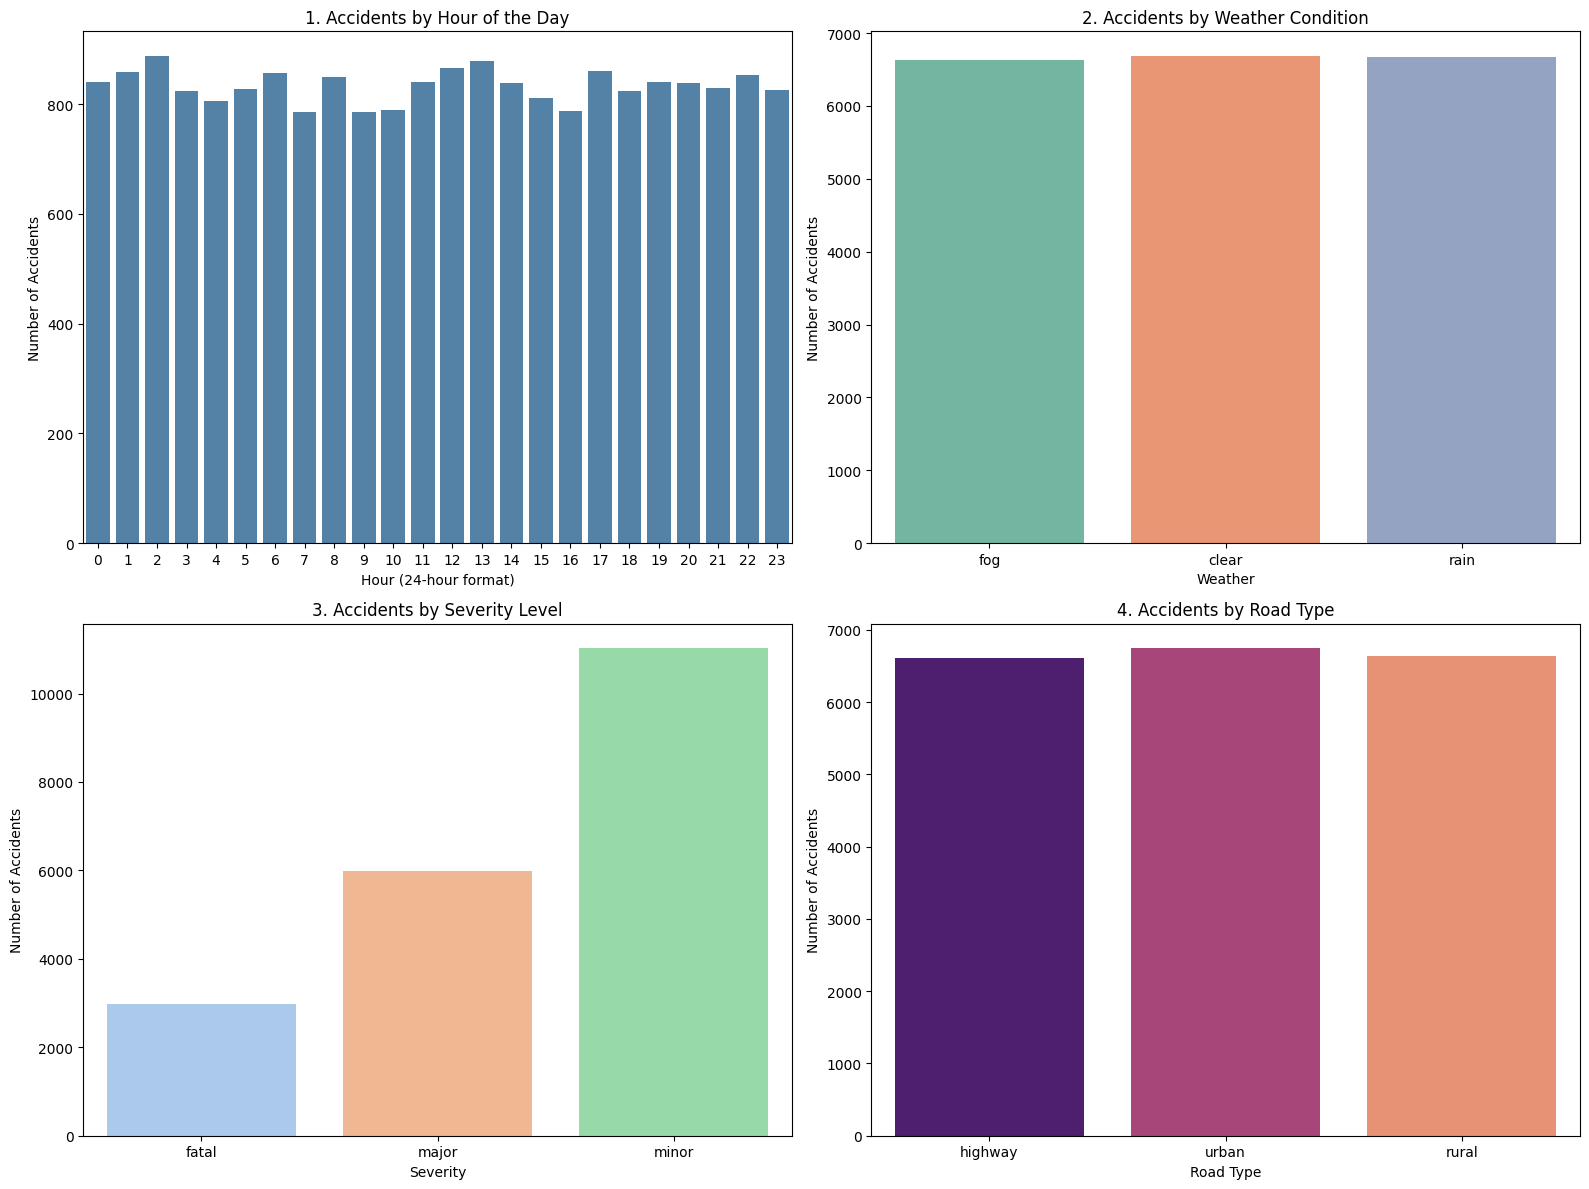

In [ ]:
# Set up the dashboard layout
plt.figure(figsize=(16, 12))

# Chart 1: Time-based (Accidents by Hour)
plt.subplot(2, 2, 1)
sns.countplot(data=df, x='hour', color='steelblue')
plt.title('1. Accidents by Hour of the Day')
plt.xlabel('Hour (24-hour format)')
plt.ylabel('Number of Accidents')

# Chart 2: Category-based (Accidents by Weather)
plt.subplot(2, 2, 2)
sns.countplot(data=df, x='weather', palette='Set2')
plt.title('2. Accidents by Weather Condition')
plt.xlabel('Weather')
plt.ylabel('Number of Accidents')

# Chart 3: Category-based (Accidents by Severity)
plt.subplot(2, 2, 3)
sns.countplot(data=df, x='accident_severity', palette='pastel')
plt.title('3. Accidents by Severity Level')
plt.xlabel('Severity')
plt.ylabel('Number of Accidents')

# Chart 4: Category-based (Accidents by Road Type)
plt.subplot(2, 2, 4)
sns.countplot(data=df, x='road_type', palette='magma')
plt.title('4. Accidents by Road Type')
plt.xlabel('Road Type')
plt.ylabel('Number of Accidents')

plt.tight_layout()
plt.show()

**Data Observations**

- The time-based analysis shows the distribution of accident frequency across the 24-hour cycle.

- Categorical grouping indicates the spread of recorded accidents under distinct weather conditions (clear, rain, fog) and on particular road types (highway, urban, rural).

- The severity breakdown highlights that minor incidents make up the majority of records in this dataset (over 55%), followed by major and fatal incidents.

- Cautious Prevention Questions for Further Investigation

- Could improved street lighting or traffic pacing during specific hours help reduce accident frequency?

- Do specific weather conditions (like rain or fog) warrant temporary speed limit reductions on high-risk road types?